# Phase 2 - Data Preprocessing

## 2.1 - Data Preprocessing Implementation
### **A) Training and test split**

We use approximately 80% of the units for training and 20% for testing, with `random_state=42`. All readings of one unit are in the same set. This is to prevent leaking units between the training and testing set and to evaluate generalization to unseen units. The row proportions can differ slightly from 80/20 because units have different numbers of readings.

We inspect and compare preprocessing using training data only.


In [1]:
%matplotlib inline

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler, PowerTransformer, QuantileTransformer
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder
from sklearn.utils.validation import check_array, check_is_fitted

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 35)

# Support running from the project folder or the neighbouring IAU workspace.
data_dir = next((base / "141" for base in [
    Path.cwd(), Path.cwd() / "iau_project", Path.cwd() / "IAU-project",
    Path.cwd().parent / "iau_project",
] if all((base / "141" / name).is_file()
         for name in ["readings.csv", "units.csv", "gateways.csv"])), None)
if data_dir is None:
    raise FileNotFoundError("Cannot find all three dataset files in the 141 folder.")

readings = pd.read_csv(data_dir / "readings.csv", sep="\t")
units = pd.read_csv(data_dir / "units.csv", sep=",")
gateways = pd.read_csv(data_dir / "gateways.csv", sep=";")

sensor_cols = ["current_motor", "dp_filter", "oilTemperature", "reservoir_pressure",
               "vibration_rms", "Flowmeter", "temp_bearing", "dewpointDischarge", "auxCurrent"]

In [2]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_index, test_index = next(splitter.split(readings, groups=readings['unitId']))

train_readings = readings.iloc[train_index].copy()
test_readings = readings.iloc[test_index].copy()
assert set(train_readings['unitId']).isdisjoint(test_readings['unitId'])
assert len(train_readings) + len(test_readings) == len(readings)

split_summary = pd.DataFrame([
    {'set': name, 'rows': len(frame), 'units': frame['unitId'].nunique(),
     'row_percent': 100 * len(frame) / len(readings)}
    for name, frame in [('Training', train_readings), ('Test (reserved)', test_readings)]
])
display(split_summary.round(2))


,set,rows,units,row_percent
0,Training,12097,1699,80.22
1,Test (reserved),2983,425,19.78


In [3]:
training_target = train_readings['failure'].value_counts().sort_index()
display(pd.DataFrame({'training_rows': training_target,
                      'percent': 100 * training_target / len(train_readings)}).round(2))


,training_rows,percent
failure,,
0,10588,87.53
1,1509,12.47


### **B) Data format and initial cleaning**

We reproduce the following formatting rules from Phase 1: normalization of unit IDs, parsing the known date formats, removing exact duplicate readings after unit ID normalization, and exclusion of readings whose unit commission year is later than their observation year.

We add `model_code`, `fleet_code`, `class_duty` and `commissionYear` through a many-to-one left join. Unmatched readings are retained.

Gateway snapshots postdate all readings. The historical timing of service hours and overhaul dates is also uncertain. We leave those fields out at this stage. This predictor set will be narrowed down in Section 2.2.

In [4]:
def parse_dates(values):
    parsed = pd.Series(pd.NaT, index=values.index, dtype="datetime64[ns]")
    for fmt in ["%Y-%m-%d", "%m/%d/%Y, %H:%M:%S", "%d %b %Y", "%Y/%m/%d"]:
        parsed = parsed.fillna(pd.to_datetime(values.str.strip(), format=fmt, errors="coerce"))
    return parsed

metadata_cols = ['model_code', 'fleet_code', 'class_duty', 'commissionYear']

def prepare_readings(frame, unit_metadata):
    prepared = frame.copy()
    prepared['unitId'] = prepared['unitId'].str.extract(r'^U(\d{5})$', expand=False).astype(int)
    prepared['tsCycle'] = parse_dates(prepared['tsCycle'])
    if prepared['tsCycle'].isna().any():
        raise ValueError('Some cycle dates do not match the documented formats.')
    before = len(prepared)
    prepared = prepared.drop_duplicates()
    duplicate_rows = before - len(prepared)
    prepared = prepared.merge(unit_metadata[['unitId'] + metadata_cols], on='unitId',
                              how='left', validate='many_to_one', indicator='unit_match')
    invalid = prepared['commissionYear'].gt(prepared['tsCycle'].dt.year)
    chronology_rows = int(invalid.sum())
    prepared = prepared.loc[~invalid].copy()
    audit = {'rows_before_cleaning': before,
             'exact_duplicates_removed': duplicate_rows,
             'chronology_conflicts_removed': chronology_rows,
             'remaining_rows': len(prepared),
             'rows_without_unit_metadata': int(prepared['unit_match'].eq('left_only').sum())}
    return prepared, audit

training, cleaning_audit = prepare_readings(train_readings, units)
assert training['failure'].isin([0, 1]).all()
display(pd.Series(cleaning_audit, name='rows').to_frame())

,rows
rows_before_cleaning,12097
exact_duplicates_removed,175
chronology_conflicts_removed,247
remaining_rows,11675
rows_without_unit_metadata,115


#### Training-only comparison of missing values and outliers

In Phase 1 Section 1.2 we analyzed two approaches to addressing readings outside of mean ± 3 standard deviations. Before definitely choosing our approach, we will compare the policy of simply removing these rows with a policy of retaining the rows and filling the missing sensor values with training medians and clipping outliers to the training limits.

All limits use population standard deviations (`ddof=0`), as in Phase 1.

This comparison isolates sensor cleaning. We retain this comparison to document the change from Phase 1. The chosen policy below keeps readings with median imputation and leaves sensor outliers unchanged.


In [5]:
training_sensors = training[sensor_cols].copy()
originally_incomplete = training_sensors.isna().any(axis=1)

na_value_mask = pd.DataFrame(False, index=training.index, columns=sensor_cols)
na_value_mask['oilTemperature'] = training_sensors['oilTemperature'].eq(-999)
na_value_mask['current_motor'] = training_sensors['current_motor'].eq(99)
training_sensors = training_sensors.mask(na_value_mask)

display(pd.DataFrame({'original_missing': training[sensor_cols].isna().sum(),
                      'suspected_missing_codes': na_value_mask.sum(),
                      'total_to_replace': training_sensors.isna().sum()}))


,original_missing,suspected_missing_codes,total_to_replace
current_motor,0,17,17
dp_filter,478,0,478
oilTemperature,0,39,39
reservoir_pressure,0,0,0
vibration_rms,461,0,461
Flowmeter,0,0,0
temp_bearing,0,0,0
dewpointDischarge,0,0,0
auxCurrent,0,0,0


**Approach 1 - Remove incomplete readings and outliers**

We remove rows with missing sensor values, replace the two suspected missing-value codes with medians, then learn the sensor means and standard deviations on the remaining training rows. A row is kept only if all nine sensor values fall strictly inside the limits established in Phase 1.

We estimate the medians after excluding the suspected codes. Exact duplicates are also removed in this phase.

In [6]:
removal_input = training_sensors.loc[~originally_incomplete].copy()
removal_imputer = SimpleImputer(strategy='median')
removal_filled = pd.DataFrame(removal_imputer.fit_transform(removal_input),
                              index=removal_input.index, columns=sensor_cols)
removal_mean = removal_filled.mean()
removal_std = removal_filled.std(ddof=0)
removal_lower = removal_mean - 3 * removal_std
removal_upper = removal_mean + 3 * removal_std

inside_limits = (removal_filled.gt(removal_lower) & removal_filled.lt(removal_upper)).all(axis=1)
sensors_removed = removal_filled.loc[inside_limits].copy()

print(f'Rows removed for missing sensor values: {originally_incomplete.sum()}')
print(f'Additional rows removed for sensor outliers: {(~inside_limits).sum()}')
print(f'Remaining training rows: {len(sensors_removed)}')


Rows removed for missing sensor values: 884
Additional rows removed for sensor outliers: 514
Remaining training rows: 10277


**Approach 2 - Retain readings with imputation and clipping**

The pipeline learns one median per sensor, followed by mean ± 3 standard deviation limits after imputation. Its `transform` method applies those saved values without fitting again. This preserves one output row per input row.

Medians and clipping limits can differ from Approach 1 because incomplete training readings are retained. Imputation can create concentrations at the median and clipping can create concentrations at the limits, so we inspect both effects.


In [7]:
class SigmaClipper(TransformerMixin, BaseEstimator):
    def __init__(self, n_std=3):
        self.n_std = n_std

    def fit(self, X, y=None):
        values = check_array(X)
        self.n_features_in_ = values.shape[1]
        self.mean_ = values.mean(axis=0)
        self.std_ = values.std(axis=0, ddof=0)
        self.lower_ = self.mean_ - self.n_std * self.std_
        self.upper_ = self.mean_ + self.n_std * self.std_
        return self

    def transform(self, X):
        check_is_fitted(self, ['lower_', 'upper_'])
        values = check_array(X)
        if values.shape[1] != self.n_features_in_:
            raise ValueError('The number of sensor columns has changed.')
        return np.clip(values, self.lower_, self.upper_)

clipping_comparison_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('clipper', SigmaClipper(n_std=3))
])
sensors_clipped = pd.DataFrame(clipping_comparison_pipeline.fit_transform(training_sensors),
                               index=training_sensors.index, columns=sensor_cols)

**Median imputation without outlier removal or clipping**

We estimate one median per sensor from the training set after masking the suspected missing-value codes. The same fitted medians can later be applied to other observations. All remaining sensor values are preserved, including values beyond the three-standard-deviation limits.


In [8]:
primary_imputer = SimpleImputer(strategy='median')
sensors_imputed = pd.DataFrame(primary_imputer.fit_transform(training_sensors),
                               index=training_sensors.index, columns=sensor_cols)
observed = training_sensors.notna().to_numpy()
assert np.array_equal(sensors_imputed.to_numpy()[observed], training_sensors.to_numpy()[observed])
assert sensors_imputed.notna().all().all()
assert len(sensors_imputed) == len(training)

print(f'Training readings retained: {len(sensors_imputed)}')
print(f'Failure readings retained: {training["failure"].sum()}')


Training readings retained: 11675
Failure readings retained: 1473


In [9]:
comparison_frames = {'Before sensor cleaning': training_sensors,
                     'Remove rows': sensors_removed,
                     'Impute and clip': sensors_clipped,
                     'Impute only': sensors_imputed}
comparison_rows = []
for name, frame in comparison_frames.items():
    labels = training.loc[frame.index, 'failure']
    comparison_rows.append({'approach': name, 'rows': len(frame),
                            'rows_removed': len(training) - len(frame),
                            'failure_0': labels.eq(0).sum(), 'failure_1': labels.eq(1).sum(),
                            'failure_percent': 100 * labels.mean(),
                            'units': training.loc[frame.index, 'unitId'].nunique()})
comparison_summary = pd.DataFrame(comparison_rows).set_index('approach')
display(comparison_summary.round(2))

removal_by_class = training.groupby('failure').size().rename('before')
removal_by_class = removal_by_class.to_frame().join(
    training.loc[sensors_removed.index].groupby('failure').size().rename('after')).fillna(0)
removal_by_class['removed_percent'] = 100 * (1 - removal_by_class['after'] / removal_by_class['before'])
display(removal_by_class.round(2))


,rows,rows_removed,failure_0,failure_1,failure_percent,units
approach,,,,,,
Before sensor cleaning,11675,0,10202,1473,12.62,1668
Remove rows,10277,1398,9348,929,9.04,1654
Impute and clip,11675,0,10202,1473,12.62,1668
Impute only,11675,0,10202,1473,12.62,1668


,before,after,removed_percent
failure,,,
0,10202,9348,8.37
1,1473,929,36.93


In [10]:
retention_imputed = pd.DataFrame(
    clipping_comparison_pipeline.named_steps['imputer'].transform(training_sensors),
    index=training_sensors.index, columns=sensor_cols)
clipper = clipping_comparison_pipeline.named_steps['clipper']

cleaning_effects = pd.DataFrame({
    'median_for_retention': clipping_comparison_pipeline.named_steps['imputer'].statistics_,
    'retention_lower_limit': clipper.lower_,
    'retention_upper_limit': clipper.upper_,
    'values_imputed': training_sensors.isna().sum(),
    'values_clipped': retention_imputed.ne(sensors_clipped).sum(),
    'removal_candidates': (~(removal_filled.gt(removal_lower) & removal_filled.lt(removal_upper))).sum()
}, index=sensor_cols)
display(cleaning_effects.round(3))


,median_for_retention,retention_lower_limit,retention_upper_limit,values_imputed,values_clipped,removal_candidates
current_motor,5.016,-0.265,10.550,17,0,0
dp_filter,21.321,-9.268,57.051,478,190,167
oilTemperature,55.095,19.817,90.428,39,41,39
reservoir_pressure,8.690,6.902,10.485,0,26,24
vibration_rms,2.716,-1.808,7.989,461,185,165
Flowmeter,27.992,16.088,39.944,0,36,32
temp_bearing,64.936,40.663,89.321,0,33,31
dewpointDischarge,8.042,-2.469,18.499,0,35,32
auxCurrent,2.502,0.025,4.977,0,37,33


In [11]:
sensor_summary = pd.concat({
    name: pd.DataFrame({'mean': frame.mean(), 'std': frame.std(ddof=0),
                        'median': frame.median(),
                        'IQR': frame.quantile(0.75) - frame.quantile(0.25),
                        'skew': frame.skew()})
    for name, frame in comparison_frames.items()
}, names=['approach', 'sensor'])
display(sensor_summary.round(3))


mean     std  median     IQR  \
approach               sensor                                               
Before sensor cleaning current_motor        5.142   1.804   5.016   2.789   
                       dp_filter           24.001  11.274  21.321  12.523   
                       oilTemperature      55.123  11.788  55.095  15.859   
                       reservoir_pressure   8.693   0.597   8.690   0.802   
                       vibration_rms        3.106   1.664   2.716   1.927   
                       Flowmeter           28.016   3.976  27.992   5.334   
                       temp_bearing        64.992   8.110  64.936  10.998   
                       dewpointDischarge    8.015   3.495   8.042   4.686   
                       auxCurrent           2.501   0.825   2.502   1.117   
Remove rows            current_motor        5.144   1.810   5.024   2.794   
                       dp_filter           23.141   9.396  21.098  12.103   
                       oilTemperature      55.174  11.506  55.131  15.651   
                       reservoir_pressure   8.699   0.592   8.700   0.802   
                       vibration_rms        2.996   1.440   2.690   1.856   
                       Flowmeter           28.064   3.927  28.029   5.349   
                       temp_bearing        64.892   7.979  64.859  10.980   
                       dewpointDischarge    8.003   3.433   8.037   4.668   
                       auxCurrent           2.493   0.810   2.494   1.104   
Impute and clip        current_motor        5.142   1.803   5.016   2.783   
                       dp_filter           23.676  10.095  21.321  11.873   
                       oilTemperature      55.124  11.737  55.095  15.813   
                       reservoir_pressure   8.693   0.597   8.690   0.802   
                       vibration_rms        3.065   1.526   2.716   1.825   
                       Flowmeter           28.017   3.971  27.992   5.334   
                       temp_bearing        64.990   8.086  64.936  10.998   
                       dewpointDischarge    8.016   3.483   8.042   4.686   
                       auxCurrent           2.501   0.824   2.502   1.117   
Impute only            current_motor        5.142   1.803   5.016   2.783   
                       dp_filter           23.891  11.053  21.321  11.873   
                       oilTemperature      55.123  11.769  55.095  15.813   
                       reservoir_pressure   8.693   0.597   8.690   0.802   
                       vibration_rms        3.091   1.633   2.716   1.825   
                       Flowmeter           28.016   3.976  27.992   5.334   
                       temp_bearing        64.992   8.110  64.936  10.998   
                       dewpointDischarge    8.015   3.495   8.042   4.686   
                       auxCurrent           2.501   0.825   2.502   1.117   

                                            skew  
approach               sensor                     
Before sensor cleaning current_motor       0.216  
                       dp_filter           1.981  
                       oilTemperature     -0.026  
                       reservoir_pressure  0.020  
                       vibration_rms       1.625  
                       Flowmeter          -0.013  
                       temp_bearing        0.030  
                       dewpointDischarge  -0.052  
                       auxCurrent          0.013  
Remove rows            current_motor       0.216  
                       dp_filter           1.040  
                       oilTemperature     -0.017  
                       reservoir_pressure  0.010  
                       vibration_rms       0.963  
                       Flowmeter           0.002  
                       temp_bearing        0.003  
                       dewpointDischarge  -0.033  
                       auxCurrent          0.011  
Impute and clip        current_motor       0.217  
                       dp_filter           1.25

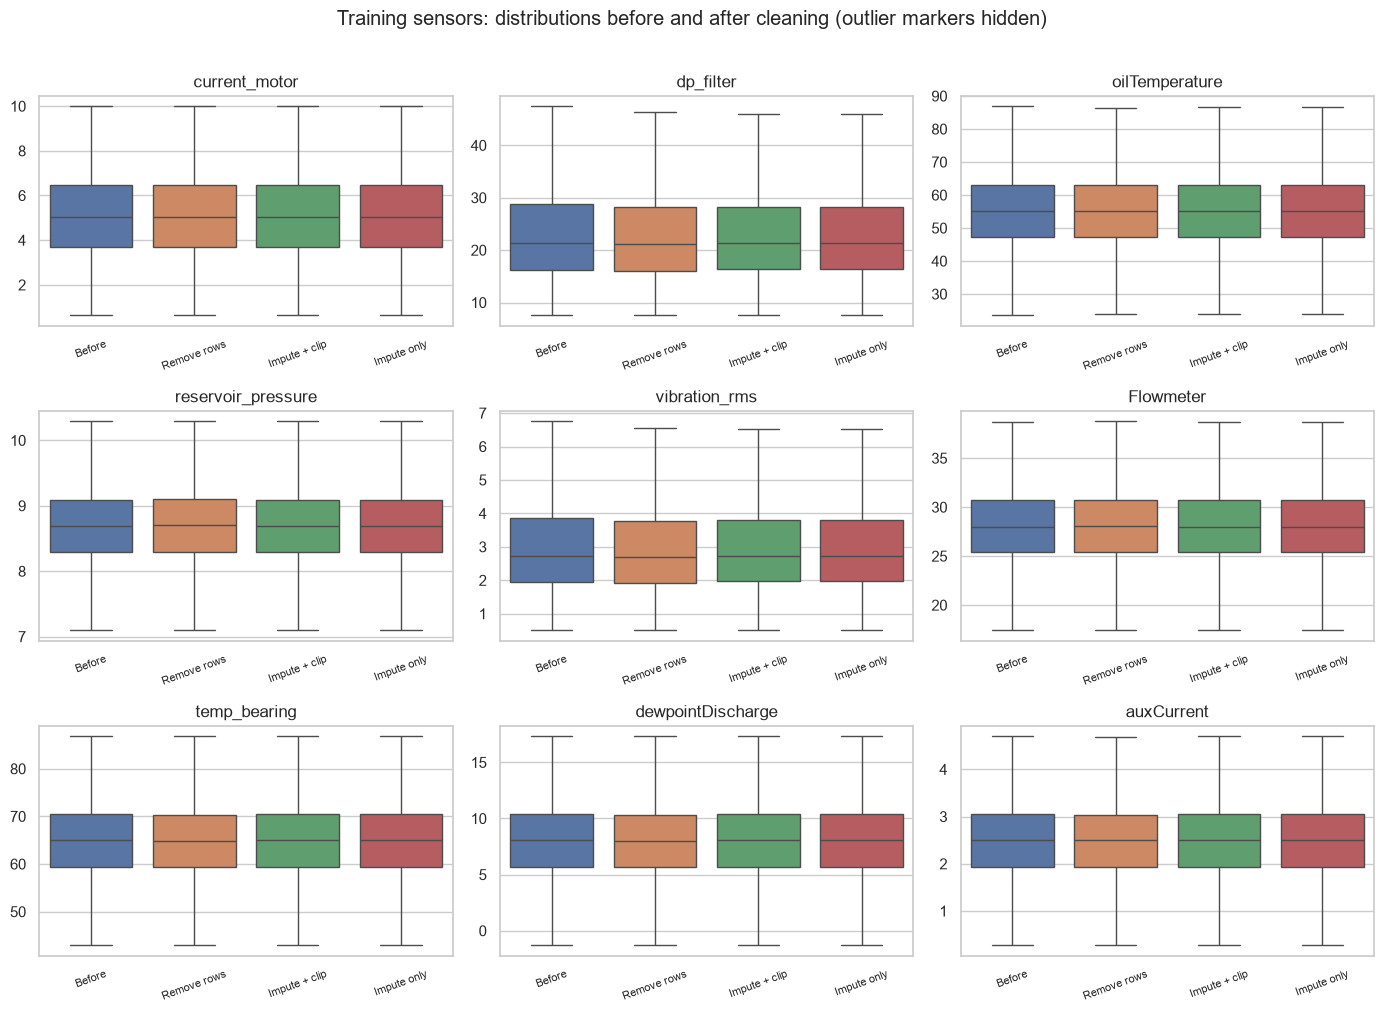

In [12]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for col, ax in zip(sensor_cols, axes.flat):
    labels = ['Before', 'Remove rows', 'Impute + clip', 'Impute only']
    plot_data = pd.DataFrame({label: frame[col] for label, frame in zip(labels, comparison_frames.values())})
    sns.boxplot(data=plot_data, showfliers=False, ax=ax)
    ax.set_title(col)
    ax.tick_params(axis='x', labelrotation=20, labelsize=8)
fig.suptitle('Training sensors: distributions before and after cleaning (outlier markers hidden)', y=1.01)
plt.tight_layout()
plt.show()


The box plots show medians and distribution spreads outlier markers are hidden. The tables include all values available in each approach.

After exact duplicate removal and the chronology check, 11,675 training readings remain. Removing incomplete readings and sensor outliers discards another 1,398 rows (12.0%), which is a rather significant amount. This also includes 544 of 1,473 failure readings (36.93%), compared to 854 of 10,202 non-failure readings (8.37%). The failure proportion therefore falls from 12.62% to 9.04%.

Imputation and clipping retains all 11,675 rows and preserves the 12.62% failure proportion. However, clipping changes 190 filter-pressure values and 185 vibration values, as well as smaller numbers for the other sensors.

We choose median imputation while retaining sensor outliers in order to preserve all 11,675 readings after the duplicate and chronology checks, as well as all 1,473 failure readings. We leave clipping as an alternative for later model comparison. While retaining extremes does not establish that they are correct, the available evidence does not justify deleting or capping them.


### Class duty grouping

In order to ascertain our assumption that categories in class duty form three groups, `light/l/1`, `normal/n/med/2`, and `heavy/h/3`, we screen all nine sensors. We use one median per training unit and exclude missing values separately for each sensor. Suspected codes `current_motor=99` and `oilTemperature=-999` are treated as missing, no sensor is clipped or imputed for this audit.

The table below reports the duty-group medians, Spearman rank correlation with the proposed groups, and the fraction of unit-median variance lying between duty groups (`eta_squared`). A fixed depth-two decision tree also predicts the three proposed duty groups from each sensor alone in five stratified folds. 

In [13]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import balanced_accuracy_score, confusion_matrix

duty_aliases = {'light': 'light', 'l': 'light', '1': 'light',
                'normal': 'normal', 'n': 'normal', 'med': 'normal', '2': 'normal',
                'heavy': 'heavy', 'h': 'heavy', '3': 'heavy'}
duty_sensor_cols = ['current_motor', 'reservoir_pressure']
duty_order = ['light', 'normal', 'heavy']
alias_order = ['light', 'l', '1', 'normal', 'n', 'med', '2', 'heavy', 'h', '3']
alias_readings = training[['unitId', 'class_duty'] + duty_sensor_cols].copy()
alias_readings['alias'] = alias_readings['class_duty'].astype('string').str.strip().str.lower()
alias_readings['mapped_duty'] = alias_readings['alias'].map(duty_aliases)
alias_readings['current_motor'] = alias_readings['current_motor'].replace(99, np.nan)
unit_alias_sensors = (alias_readings.groupby(['unitId', 'alias', 'mapped_duty'])[duty_sensor_cols]
                     .median().reset_index())

screen_readings = training[['unitId', 'class_duty'] + sensor_cols].copy()
screen_readings['alias'] = screen_readings['class_duty'].astype('string').str.strip().str.lower()
screen_readings['mapped_duty'] = screen_readings['alias'].map(duty_aliases)
screen_readings['current_motor'] = screen_readings['current_motor'].replace(99, np.nan)
screen_readings['oilTemperature'] = screen_readings['oilTemperature'].replace(-999, np.nan)
screen_readings = screen_readings.loc[screen_readings['mapped_duty'].notna()].copy()
screen_unit_sensors = (screen_readings.groupby(['unitId', 'alias', 'mapped_duty'])[sensor_cols]
                       .median().reset_index())
assert screen_unit_sensors['unitId'].is_unique
screen_duty_codes = screen_unit_sensors['mapped_duty'].map(dict(zip(duty_order, range(3))))
sensor_screen_rows = []
for sensor in sensor_cols:
    valid = screen_unit_sensors[sensor].notna()
    values = screen_unit_sensors.loc[valid, sensor]
    labels = screen_duty_codes.loc[valid]
    grand_mean = values.mean()
    total_ss = ((values - grand_mean) ** 2).sum()
    between_ss = sum(len(group) * (group.mean() - grand_mean) ** 2
                     for _, group in values.groupby(labels))
    medians = screen_unit_sensors.loc[valid].groupby('mapped_duty')[sensor].median()
    scores = cross_val_score(
        DecisionTreeClassifier(max_depth=2, min_samples_leaf=20, random_state=42),
        values.to_frame(), labels,
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
        scoring='balanced_accuracy')
    sensor_screen_rows.append({
        'sensor': sensor, 'valid_units': len(values),
        'light_median': medians['light'], 'normal_median': medians['normal'],
        'heavy_median': medians['heavy'],
        'Spearman_rho': values.corr(labels, method='spearman'),
        'eta_squared': between_ss / total_ss if total_ss > 0 else np.nan,
        'CV_balanced_accuracy': scores.mean(), 'CV_fold_SD': scores.std(ddof=0)})
sensor_screen = pd.DataFrame(sensor_screen_rows).set_index('sensor').sort_values(
    'CV_balanced_accuracy', ascending=False)
display(sensor_screen.round(4))
print('Three-class constant-prediction balanced accuracy: 0.3333')

,valid_units,light_median,normal_median,heavy_median,Spearman_rho,eta_squared,CV_balanced_accuracy,CV_fold_SD
sensor,,,,,,,,
current_motor,1568,3.4731,5.5299,7.5570,0.9334,0.9377,0.9859,0.0062
dp_filter,1568,21.0813,21.5342,21.6268,0.0444,0.0016,0.3456,0.0228
Flowmeter,1568,27.9523,28.0348,28.0001,0.0324,0.0008,0.3455,0.0208
temp_bearing,1568,64.8020,65.0143,65.0374,0.0215,0.0006,0.3407,0.0150
vibration_rms,1568,2.7304,2.7524,2.6827,-0.0165,0.0003,0.3380,0.0066
dewpointDischarge,1568,8.0492,7.9304,8.1200,0.0194,0.0013,0.3347,0.0040
oilTemperature,1568,54.9697,55.5861,55.5381,0.0167,0.0003,0.3325,0.0161
reservoir_pressure,1568,8.7000,8.6941,8.6992,-0.0026,0.0001,0.3260,0.0101
auxCurrent,1568,2.4966,2.4935,2.4973,0.0145,0.0005,0.3149,0.0146


Three-class constant-prediction balanced accuracy: 0.3333


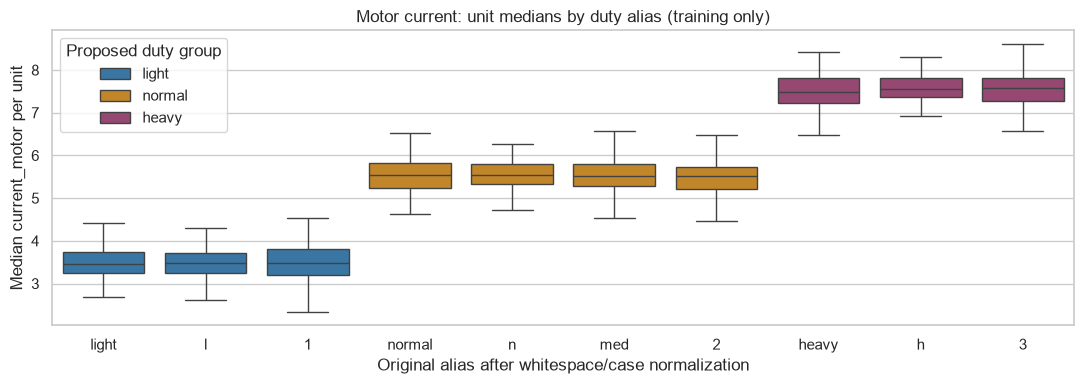

In [14]:
duty_palette = {'light': '#2878B5', 'normal': '#D98C10', 'heavy': '#A23B72'}
fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(data=unit_alias_sensors, x='alias', y='current_motor', order=alias_order,
            hue='mapped_duty', hue_order=duty_order, palette=duty_palette,
            dodge=False, showfliers=False, ax=ax)
ax.set_title('Motor current: unit medians by duty alias (training only)')
ax.set_xlabel('Original alias after whitespace/case normalization')
ax.set_ylabel('Median current_motor per unit')
ax.legend(title='Proposed duty group')
plt.tight_layout()
plt.show()

The motor-current distributions form three clear groups: `light/l/1`, `normal/n/med/2`, and `heavy/h/3`. Their alias medians are approximately **3.47 to 3.48**, **5.51 to 5.54**, and **7.49 to 7.58**, respectively. The within-group differences are much smaller than the approximately two-unit gaps between adjacent duty groups.

#### Metadata and numerical representation

`model_code` and `fleet_code` are nominal categories, for which we use one-hot encoding. We give `class_duty` the order `light < normal < heavy` and encode it using ordinal encoding.

`commissionYear` remains numerical. Its missing values can use the training median. The 115 readings without matched unit metadata are retained.

In [15]:
nominal_cols = ['model_code', 'fleet_code']
category_cols = nominal_cols + ['class_duty']
numeric_cols = sensor_cols + ['commissionYear']
feature_cols = numeric_cols + category_cols

def normalize_predictors(frame):
    normalized = frame.copy()
    normalized['oilTemperature'] = normalized['oilTemperature'].replace(-999, np.nan)
    normalized['current_motor'] = normalized['current_motor'].replace(99, np.nan)
    for col in category_cols:
        values = normalized[col].astype('string').str.strip()
        if col == 'class_duty':
            values = values.str.lower().replace(duty_aliases)
        normalized[col] = values.astype(object).where(values.notna(), np.nan)
    return normalized

X_train = training[feature_cols].copy()
y_train = training['failure'].astype(int).copy()
train_groups = training['unitId'].copy()
normalized_training = normalize_predictors(X_train)

display(pd.DataFrame({'dtype': normalized_training.dtypes.astype(str),
                      'missing': normalized_training.isna().sum(),
                      'unique_non_missing': normalized_training.nunique()}))
display(normalized_training['class_duty'].value_counts(dropna=False).rename('training_rows').to_frame())


,dtype,missing,unique_non_missing
current_motor,float64,17,11556
dp_filter,float64,478,11174
oilTemperature,float64,39,11610
reservoir_pressure,float64,0,11335
vibration_rms,float64,461,11074
Flowmeter,float64,0,11608
temp_bearing,float64,0,11650
dewpointDischarge,float64,0,11605
auxCurrent,float64,0,11433
commissionYear,float64,115,12


,training_rows
class_duty,
light,4753
normal,4175
heavy,2632
NaN,115


#### Ordinal encoding of duty

We use an explicit order with `OrdinalEncoder`: `light = 0`, `normal = 1`, `heavy = 2`. All aliases are normalized to the corresponding canonical label first, so they receive the same code.

This is reasonable because duty describes ordered levels. One-hot duty encoding remains a useful alternative for later grouped cross-validation.

Missing or previously unseen duty labels receive **`-1`**, a reserved unavailable-value code. Models can however still interpret its numerical position, so that handling should also be reviewed during model selection. The nominal model/fleet fields retain one-hot encoding, with `<missing>` for absent values and all-zero encoding for unseen labels. The transformer below is fitted on training metadata only and can transform future data without refitting. For validation, clone and fit it inside each training fold.

In [16]:
metadata_encoder = ColumnTransformer([
    ('nominal', Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='<missing>')),
        ('one_hot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ]), nominal_cols),
    ('duty', OrdinalEncoder(categories=[duty_order + [np.nan]],
                            handle_unknown='use_encoded_value', unknown_value=-1,
                            encoded_missing_value=-1, dtype=np.int64), ['class_duty'])
], remainder='drop', verbose_feature_names_out=False)

encoded_training_metadata = pd.DataFrame(
    metadata_encoder.fit_transform(normalized_training[category_cols]),
    index=normalized_training.index, columns=metadata_encoder.get_feature_names_out())
encoded_training_metadata['class_duty'] = encoded_training_metadata['class_duty'].astype('int64')
duty_encoder = metadata_encoder.named_transformers_['duty']

encoding_summary = (normalized_training[['class_duty']].rename(columns={'class_duty': 'duty'})
                    .assign(ordinal_code=encoded_training_metadata['class_duty'])
                    .groupby(['duty', 'ordinal_code'], dropna=False).size()
                    .rename('training_rows').reset_index().sort_values('ordinal_code'))
display(encoding_summary)
display(encoded_training_metadata.head())

,duty,ordinal_code,training_rows
3,NaN,-1,115
1,light,0,4753
2,normal,1,4175
0,heavy,2,2632


,model_code_<missing>,model_code_APU-12,model_code_APU-15,model_code_APU-20,model_code_XC-7,fleet_code_<missing>,fleet_code_FA,fleet_code_FB,fleet_code_FC,fleet_code_FD,fleet_code_FE,class_duty
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1
1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1
2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,2
3,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1


### **C) Scaling and attribute transformations**

We compare two scalers on the same imputed training sensors:

`StandardScaler` subtracts the training mean and divides by the training standard deviation. Extreme values can influence both estimates. \
`RobustScaler` subtracts the training median and divides by the interquartile range. It preserves extreme values rather than clipping them.

Neither scaler changes a feature's distribution shape or removes its outliers. Sensor units differ, so scaling is useful for methods that depend on distances.

In [17]:
scalers = {'StandardScaler': StandardScaler(), 'RobustScaler': RobustScaler()}
scaled_training = {}
for name, scaler in scalers.items():
    scaled_training[name] = pd.DataFrame(scaler.fit_transform(sensors_imputed),
                                         index=sensors_imputed.index, columns=sensor_cols)

scaling_summary = pd.concat({
    name: pd.DataFrame({'mean': frame.mean(), 'std': frame.std(ddof=0),
                        'median': frame.median(),
                        'IQR': frame.quantile(0.75) - frame.quantile(0.25),
                        'min': frame.min(), 'max': frame.max()})
    for name, frame in scaled_training.items()
}, names=['scaler', 'sensor'])
display(scaling_summary.round(3))


mean    std  median    IQR    min    max
scaler         sensor                                                       
StandardScaler current_motor      -0.000  1.000  -0.070  1.544 -2.503  2.695
               dp_filter           0.000  1.000  -0.233  1.074 -1.480  8.695
               oilTemperature      0.000  1.000  -0.002  1.344 -3.409  3.388
               reservoir_pressure -0.000  1.000  -0.006  1.344 -3.494  3.026
               vibration_rms       0.000  1.000  -0.230  1.117 -1.587  6.681
               Flowmeter           0.000  1.000  -0.006  1.341 -3.274  3.014
               temp_bearing       -0.000  1.000  -0.007  1.356 -3.862  4.228
               dewpointDischarge   0.000  1.000   0.008  1.341 -4.674  4.650
               auxCurrent          0.000  1.000   0.001  1.354 -3.030  3.716
RobustScaler   current_motor       0.045  0.648   0.000  1.000 -1.576  1.791
               dp_filter           0.216  0.931   0.000  1.000 -1.161  8.311
               oilTemperature      0.002  0.744   0.000  1.000 -2.536  2.523
               reservoir_pressure  0.004  0.744   0.000  1.000 -2.596  2.256
               vibration_rms       0.206  0.895   0.000  1.000 -1.214  6.184
               Flowmeter           0.005  0.745   0.000  1.000 -2.436  2.251
               temp_bearing        0.005  0.737   0.000  1.000 -2.843  3.123
               dewpointDischarge  -0.006  0.746   0.000  1.000 -3.492  3.462
               auxCurrent         -0.001  0.739   0.000  1.000 -2.240  2.745

We also compare two fitted transformers:

`PowerTransformer(method='yeo-johnson', standardize=False)` learns a monotonic power transformation. It can handle zero and negative values but changes skewness. Standardization is disabled here to separate its effect from scaling. \
`QuantileTransformer(output_distribution='normal')` learns the empirical training distribution and maps ranks to normal quantiles. It changes distances and can compress tails. Equal input values remain tied, including concentrations introduced by imputation.

In [18]:
transformers = {
    'Yeo-Johnson': PowerTransformer(method='yeo-johnson', standardize=False),
    'Normal quantiles': QuantileTransformer(n_quantiles=min(1000, len(sensors_imputed)),
                                            output_distribution='normal', random_state=42)
}
transformed_training = {}
for name, transformer in transformers.items():
    transformed_training[name] = pd.DataFrame(transformer.fit_transform(sensors_imputed),
                                               index=sensors_imputed.index, columns=sensor_cols)

skew_comparison = pd.DataFrame({'Imputed input': sensors_imputed.skew(), **{
    name: frame.skew() for name, frame in transformed_training.items()
}})
display(skew_comparison.round(3))
display(pd.Series(transformers['Yeo-Johnson'].lambdas_, index=sensor_cols,
                  name='learned_Yeo_Johnson_lambda').round(3).to_frame())


,Imputed input,Yeo-Johnson,Normal quantiles
current_motor,0.217,-0.040,0.044
dp_filter,2.045,0.010,0.017
oilTemperature,-0.026,0.002,-0.039
reservoir_pressure,0.020,-0.001,0.108
vibration_rms,1.680,0.008,0.040
Flowmeter,-0.013,-0.001,0.040
temp_bearing,0.030,-0.000,-0.011
dewpointDischarge,-0.052,0.001,0.004
auxCurrent,0.013,-0.004,-0.144


,learned_Yeo_Johnson_lambda
current_motor,0.544
dp_filter,-0.404
oilTemperature,1.041
reservoir_pressure,0.882
vibration_rms,-0.385
Flowmeter,1.028
temp_bearing,0.919
dewpointDischarge,1.034
auxCurrent,0.977


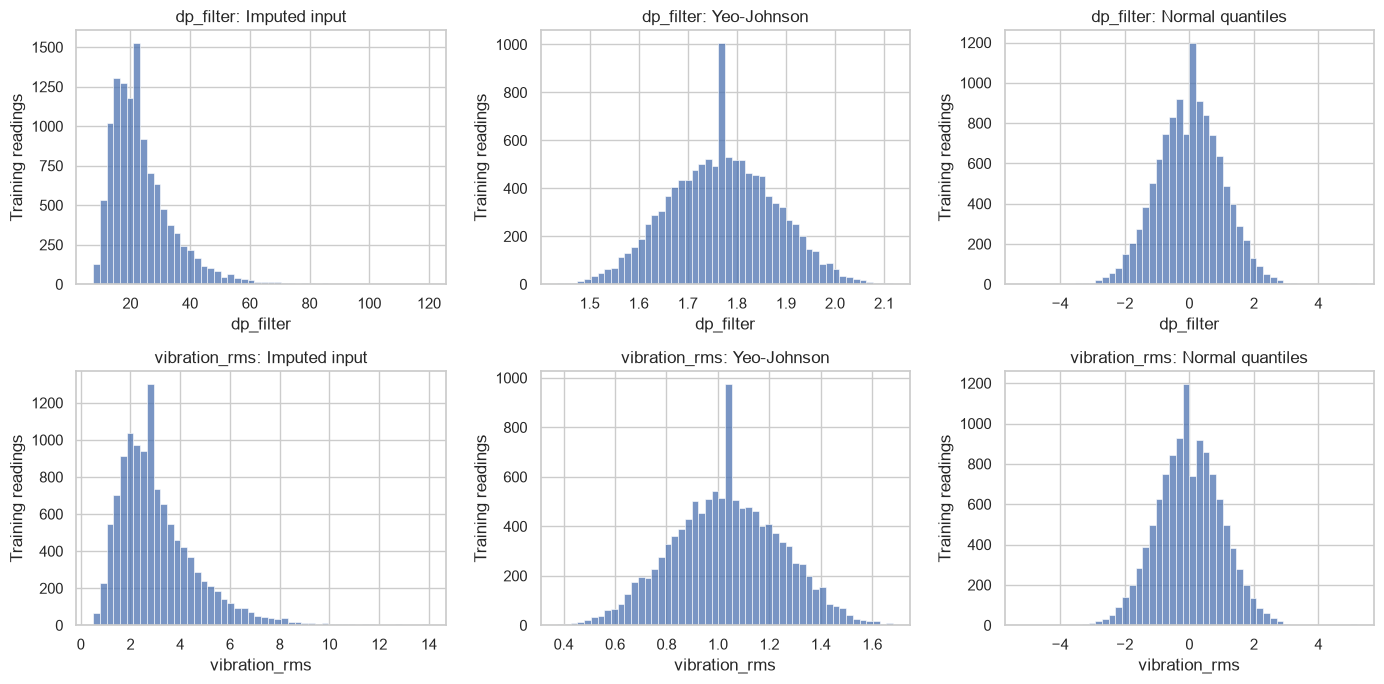

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for row, col in enumerate(['dp_filter', 'vibration_rms']):
    versions = [('Imputed input', sensors_imputed), *transformed_training.items()]
    for ax, (name, frame) in zip(axes[row], versions):
        sns.histplot(frame[col], bins=50, ax=ax)
        ax.set_title(f'{col}: {name}')
        ax.set_ylabel('Training readings')
plt.tight_layout()
plt.show()


The scaler table checks the intended effects: standard scaling gives a training mean near zero and standard deviation near one, robust scaling gives a median near zero and an IQR near one.

The transformer table and histograms show their effects on the two right-skewed sensors. All fitted parameters come from training observations. The quantile transformer maps future values outside its fitted range to the end of that range, though this may suppress differences between high readings.

### **D) Decisions and their justification**

| Decision | Reason |
|---|---|
| Split 80/20 by unit | Keep repeated observations from the same APU together, evaluation on unseen units. |
| Reload original data | Refit medians, scales and transformation parameters using training observations only. |
| Remove exact duplicates and chronology conflicts | Continue the fixed Phase 1 Section 1.2 quality rules. |
| Retain missing-sensor rows and sensor outliers | Broad removal disproportionately discards failure readings, instead impute suspected missing codes and actual missing values with training medians. |
| Add model, fleet, duty and commission year | Add the agreed unit context through a many-to-one join while retaining unmatched readings. |
| Class duty grouping | Motor current is the strongest indication. Pressure and other sensors do not independently prove or disprove the mapping. |
| Ordinal encode duty, one-hot encode model and fleet | Class duty uses three categories with (seemingly) logical scaling (lightweight < mediumweight < heavyweight). Model and fleet codes are all independent, so using one-hot makes the most sense. |
| Use RobustScaler as the initial baseline | Scales numerical features using training medians and IQRs while retaining extreme values. |

During later training and validation, each candidate pipeline must be fitted again inside the training fold, keeping all readings of a unit together. The test set remains reserved.